# Determinants of Corporate Capital Structure
### Compustat North America, FY2010–2020

**Question.** Which balance-sheet characteristics explain how much debt a firm carries?

**Data.** Annual fundamentals for US and Canadian non-financial firms, queried directly from
Compustat on Wharton Research Data Services (WRDS). Nothing is downloaded by hand.

**Roadmap.**
1. Download the raw data through the WRDS API.
2. Inspect it: coverage, missing values, where the data come from.
3. Clean it one documented step at a time, showing the evidence behind each choice.
4. Explore the outcome and its relationship with each determinant.
5. Estimate pooled OLS, OLS with industry and year effects, and firm fixed effects, then interpret.

**Headline results** (36,718 firm-years, 5,822 firms):
- Larger firms, firms with more tangible assets and firms in high-leverage industries borrow more.
- More profitable and cash-rich firms borrow less, which is consistent with the pecking-order theory.
- The pooled OLS explains **21%** of the variation in leverage (**25%** with industry and year effects).
  Most of the variation is persistent firm-level heterogeneity: firm fixed effects absorb it, and
  within a firm, year-to-year changes in the predictors explain only about 3% of changes in leverage.

## 1. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "compustat_funda.parquet"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 20)

In [2]:
import matplotlib.pyplot as plt

# Plot style: light surface, recessive grid, one blue for single-series charts.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

## 2. Data: query Compustat through the WRDS API

The query pulls the Compustat Fundamentals Annual table (`comp.funda`) with the standard filters
for a clean firm-year panel: industrial format (`INDL`), standardized data (`STD`), domestic
population (US and Canada, `D`), and consolidated statements (`C`). The SIC industry code comes
from the company header table. FY2009 is included only so that one-year lagged predictors exist
for FY2010.

**Credentials.** Set `WRDS_USERNAME` and store your password in `~/.pgpass` (run
`wrds.Connection().create_pgpass_file()` once interactively). The result is cached to
`data/raw/`, so the query runs only once. Compustat data are licensed and are not committed to
this repository.

In [3]:
FUNDA_ITEMS = {
    "at": "Total assets", "dltt": "Long-term debt", "dlc": "Debt in current liabilities",
    "ppent": "Net PP&E", "oibdp": "Operating income before depreciation (EBITDA)",
    "sale": "Net sales", "che": "Cash & short-term investments", "xrd": "R&D expense",
    "ceq": "Common equity (book)", "csho": "Shares outstanding (millions)",
    "prcc_f": "Share price, fiscal year-end", "dvc": "Common dividends",
}

QUERY = f"""
SELECT f.gvkey, f.datadate, f.fyear, f.conm, f.fic, f.curcd, c.sic,
       {", ".join("f." + c for c in FUNDA_ITEMS)}
FROM comp.funda AS f
LEFT JOIN comp.company AS c ON f.gvkey = c.gvkey
WHERE f.indfmt = 'INDL' AND f.datafmt = 'STD' AND f.popsrc = 'D' AND f.consol = 'C'
  AND f.fyear BETWEEN 2009 AND 2020
"""


def download_compustat(path: Path = RAW_FILE) -> pd.DataFrame:
    import wrds

    db = wrds.Connection(wrds_username=os.environ.get("WRDS_USERNAME"))
    try:
        df = db.raw_sql(QUERY, date_cols=["datadate"])
    finally:
        db.close()
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False)
    return df


raw = pd.read_parquet(RAW_FILE) if RAW_FILE.exists() else download_compustat()
# WRDS returns nullable dtypes; plain floats make the ratio arithmetic predictable.
raw = raw.astype({c: float for c in FUNDA_ITEMS}).assign(
    fyear=lambda d: d["fyear"].astype(int), sic=lambda d: pd.to_numeric(d["sic"], errors="coerce"))
print(f"{len(raw):,} firm-years, {raw['gvkey'].nunique():,} firms, FY{raw['fyear'].min()}-{raw['fyear'].max()}")
raw.head()

136,665 firm-years, 20,172 firms, FY2009-2020


,gvkey,datadate,fyear,conm,tic,fic,curcd,sic,naics,at,...,ppent,oibdp,ni,sale,che,xrd,ceq,csho,prcc_f,dvc
0,001004,2010-05-31,2009,AAR CORP,AIR,USA,USD,5080,423860,"1,501.042",...,334.430,134.345,44.628,"1,352.151",79.370,NaN,746.906,39.484,19.700,0.000
1,001013,2009-09-30,2009,ADC TELECOMMUNICATIONS INC,ADCT.1,USA,USD,3661,334210,"1,343.600",...,163.400,84.700,-474.300,996.700,535.500,65.300,356.200,96.600,8.340,0.000
2,001019,2009-12-31,2009,AFA PROTECTIVE SYSTEMS INC,AFAP,USA,USD,7380,561621,32.678,...,9.557,5.956,2.155,78.073,5.493,NaN,8.762,0.153,255.000,0.307
3,001045,2009-12-31,2009,AMERICAN AIRLINES GROUP INC,AAL,USA,USD,4512,481111,"25,438.000",...,"15,476.000",262.000,"-1,468.000","19,917.000","4,859.000",NaN,"-3,489.000",332.624,7.730,0.000
4,001050,2009-12-31,2009,CECO ENVIRONMENTAL CORP,CECO,USA,USD,3564,333413,77.515,...,11.362,3.799,-15.032,138.985,1.393,0.022,31.760,14.289,3.950,0.000


## 3. First look at the raw data

Before cleaning, check what the query actually returned: how complete each item is, and which
kinds of companies are in the file.

In [4]:
missing = pd.DataFrame({
    "description": pd.Series(FUNDA_ITEMS),
    "% missing (all rows)": raw[list(FUNDA_ITEMS)].isna().mean() * 100,
    "% missing (non-financial SIC)": raw.loc[~raw["sic"].between(6000, 6999), list(FUNDA_ITEMS)].isna().mean() * 100,
}).sort_values("% missing (all rows)", ascending=False)
missing.round(1)

,description,% missing (all rows),% missing (non-financial SIC)
xrd,R&D expense,66.600,50.700
oibdp,Operating income before depreciation (EBITDA),27.100,4.100
ppent,Net PP&E,26.400,3.500
dvc,Common dividends,25.700,4.900
sale,Net sales,24.900,3.900
dltt,Long-term debt,24.700,3.700
ceq,Common equity (book),24.600,3.600
dlc,Debt in current liabilities,24.500,3.400
che,Cash & short-term investments,24.500,3.400
at,Total assets,24.500,3.400


**Interpretation.**
- About a quarter of all rows have no balance sheet at all: total assets are missing for 24.5%.
  These rows are concentrated among financial SIC codes, mostly investment funds and ETFs (for
  example "iShares Core S&P Small-Cap ETF"), which file with Compustat but are not operating
  companies. Among non-financial firms, total assets are missing for only about 3% of rows.
- **R&D** is missing for two-thirds of rows. Compustat leaves `xrd` blank when a firm does not
  report R&D separately, and many firms simply do no R&D. Dropping these rows would throw away
  most of the sample, so R&D is handled separately (step 4.6).
- **Share price** (`prcc_f`) is missing more often than the accounting items, mainly for firms
  without a traded share price. This affects only the market-to-book ratio.

In [5]:
raw["fic"].value_counts().head(8).rename("firm-years").to_frame().assign(
    share=lambda d: (100 * d["firm-years"] / len(raw)).round(1))

,firm-years,share
fic,,
USA,97094,71.000
CAN,26714,19.500
CYM,2594,1.900
ISR,1141,0.800
BMU,990,0.700
GBR,977,0.700
VGB,749,0.500
MHL,533,0.400


`fic` is the country of incorporation. The "domestic" population is defined by where the firm
files, so it also contains companies incorporated offshore (Cayman Islands, Israel, Bermuda, ...).
The assignment asks for North American companies, so the sample is restricted to US and
Canadian incorporations. About 18% of the rows report in Canadian dollars. That does not matter
for ratios, which are currency-free; a CAD-reporter control absorbs the level difference in log
assets.

## 4. Cleaning, step by step

Each step records how many firm-years survive, building the sample-selection table in 4.10.

### 4.1 Keep companies incorporated in the US or Canada

In [6]:
steps = [("Compustat firm-years, FY2009-2020", len(raw))]
df = raw[raw["fic"].isin(["USA", "CAN"])].copy()
steps.append(("Incorporated in the US or Canada", len(df)))
print(f"{len(raw) - len(df):,} rows removed, {len(df):,} remain")

12,857 rows removed, 123,808 remain


### 4.2 Remove financial firms and utilities

Banks, insurers and investment vehicles hold debt as part of their business model, and utility
leverage is set largely by rate regulators. Their debt ratios measure something different from an
industrial firm's financing choice, which is why the capital-structure literature excludes them.

In [7]:
df["leverage_raw"] = (df["dltt"] + df["dlc"]) / df["at"]
group = np.select([df["sic"].between(6000, 6999), df["sic"].between(4900, 4949)],
                  ["Financials (SIC 6000-6999)", "Utilities (SIC 4900-4949)"], "All other industries")
df.groupby(group).agg(firm_years=("gvkey", "size"),
                      share_missing_assets=("at", lambda s: s.isna().mean()),
                      median_leverage=("leverage_raw", "median"))

,firm_years,share_missing_assets,median_leverage
All other industries,70523,0.037,0.177
Financials (SIC 6000-6999),50021,0.610,0.116
Utilities (SIC 4900-4949),3264,0.013,0.332


Financial SIC codes make up about 40% of the rows. Most of them are funds with no balance-sheet
data, which explains the missing-asset share. Utilities have a median debt ratio of 0.33, almost
twice that of other industries, which confirms that their leverage behaves differently. Both
groups are removed.

In [8]:
df = df[~(df["sic"].between(6000, 6999) | df["sic"].between(4900, 4949))]
steps.append(("Excluding financials and utilities", len(df)))
print(f"{len(df):,} firm-years remain")

70,523 firm-years remain


### 4.3 Remove micro-firms and rows without debt data

Ratios with a tiny denominator explode. Compare leverage for firms below and above $10 million in
total assets, a common cut-off in empirical corporate finance:

In [9]:
has_assets = df[df["at"] > 0]
size_class = np.where(has_assets["at"] < 10, "Assets < $10M", "Assets >= $10M")
pd.concat({
    "leverage": has_assets.groupby(size_class)["leverage_raw"].describe(percentiles=[0.5, 0.99]),
    "EBITDA / assets": (has_assets["oibdp"] / has_assets["at"]).groupby(size_class).describe(percentiles=[0.5, 0.99]),
}, axis=1).T.round(2)

Assets < $10M  Assets >= $10M
leverage        count     13,411.000      53,771.000
                mean           9.800           0.250
                std          101.460           0.320
                min            0.000          -0.050
                50%            0.130           0.180
                99%          192.180           1.330
                max        6,318.000           9.340
EBITDA / assets count     13,178.000      53,772.000
                mean         -12.000          -0.010
                std          112.260           0.350
                min       -5,325.500         -31.680
                50%           -0.950           0.080
                99%            0.430           0.390
                max        1,106.000           3.560

Below $10M, average leverage is about 10 (debt ten times assets), the 99th percentile is near 200,
and the *median* firm loses almost its entire asset base in a year (EBITDA/assets ≈ −95%). These
are mostly shell companies and pre-revenue start-ups. They would dominate any least-squares fit
while saying little about the typical firm's financing decision. Above $10M the distribution is
well behaved, with a median of 0.18 and a 99th percentile of 1.33.

This step also requires positive sales, which removes non-operating shells, and non-missing debt
items, since the dependent variable cannot be built without them.

In [10]:
df = df[(df["at"] >= 10) & (df["sale"] > 0) & df["dltt"].notna() & df["dlc"].notna()]
steps.append(("Assets >= $10M, positive sales, debt reported", len(df)))
print(f"{len(df):,} firm-years remain")

48,070 firm-years remain


### 4.4 Check for duplicate firm-years

In [11]:
dupes = df.duplicated(["gvkey", "fyear"]).sum()
print(f"Duplicate (gvkey, fyear) pairs: {dupes}")
df = df.sort_values(["gvkey", "fyear"]).drop_duplicates(["gvkey", "fyear"], keep="last")

Duplicate (gvkey, fyear) pairs: 0


There are none. A firm that changes its fiscal year-end can in principle appear twice in one
fiscal year, but the standardized-data filter already prevents it here. The panel index
(`gvkey`, `fyear`) is unique.

### 4.5 Construct the variables

| Variable | Definition | Expected sign | Rationale |
|---|---|---|---|
| **Leverage** (outcome) | (DLTT + DLC) / AT | | Book debt ratio |
| Size | log(AT) | + | Large firms are diversified and face lower bankruptcy costs (trade-off) |
| Tangibility | PPENT / AT | + | Tangible assets serve as collateral (trade-off) |
| Profitability | OIBDP / AT | − | Profitable firms fund themselves internally (pecking order) |
| Market-to-book | (AT − CEQ + CSHO × PRCC_F) / AT | − | Growth options are lost in distress, so growth firms borrow less |
| Cash | CHE / AT | − | Liquid assets substitute for debt |
| R&D intensity | XRD / AT | − | Intangible, firm-specific investment supports little debt |
| Dividend payer | 1 if DVC > 0 | − | Payers tend to be mature firms with less information asymmetry |
| Industry leverage | Median leverage of the 2-digit SIC industry-year | + | Captures industry-wide debt capacity |

Every ratio is scaled by total assets so that firms of different sizes are comparable.

In [12]:
df = df.assign(
    leverage=(df["dltt"] + df["dlc"]) / df["at"],
    size=np.log(df["at"]),
    tangibility=df["ppent"] / df["at"],
    profitability=df["oibdp"] / df["at"],
    market_to_book=(df["at"] - df["ceq"] + df["csho"] * df["prcc_f"]) / df["at"],
    cash=df["che"] / df["at"],
    rd_intensity=df["xrd"] / df["at"],
    dividend_payer=(df["dvc"].fillna(0) > 0).astype(int),
    cad_reporter=(df["curcd"] == "CAD").astype(int),
    sic2=(df["sic"] // 100).astype(int),
)

# Sanity check against a firm whose numbers are easy to verify: Apple, FY2020.
cols = ["at", "dltt", "dlc", "leverage", "size", "tangibility", "profitability", "market_to_book", "cash", "rd_intensity"]
df.loc[(df["gvkey"] == "001690") & (df["fyear"] == 2020), ["conm"] + cols]

,conm,at,dltt,dlc,leverage,size,tangibility,profitability,market_to_book,cash,rd_intensity
124807,APPLE INC,"323,888.000","107,049.000","15,229.000",0.378,12.688,0.140,0.235,6.869,0.281,0.058


Apple's FY2020 values match its 10-K: $324bn of assets, a debt ratio of 0.38, EBITDA of 23% of
assets, cash of 28% of assets, and a market-to-book of about 6.9. The formulas behave as intended.

### 4.6 Missing values in the constructed variables

In [13]:
VARS = ["leverage", "size", "tangibility", "profitability", "market_to_book", "cash", "rd_intensity"]
pd.DataFrame({"% missing": df[VARS].isna().mean() * 100}).round(2).T

,leverage,size,tangibility,profitability,market_to_book,cash,rd_intensity
% missing,0.000,0.000,0.060,0.100,8.970,0.000,43.820


In [14]:
xrd_status = np.select([df["xrd"].isna(), df["xrd"] == 0], ["not reported", "reported as zero"], "positive")
pd.crosstab(xrd_status, df["sic2"].between(28, 38).map({True: "High-tech manufacturing (SIC 28-38)",
                                                        False: "All other industries"}), normalize="columns").round(3)

sic2,All other industries,High-tech manufacturing (SIC 28-38)
row_0,,
not reported,0.606,0.161
positive,0.241,0.830
reported as zero,0.154,0.009


**Interpretation and treatment.**
- **R&D (44% missing).** Missing R&D is concentrated outside the R&D-intensive industries
  (chemicals, pharma, machinery, electronics), so a blank almost always means "no material R&D",
  not "unknown". Following standard practice, missing R&D is set to **0**, and an indicator
  `rd_missing` is added. The indicator lets the model treat "not reported" differently from a
  reported zero rather than forcing the two to be identical.
- **Market-to-book (9% missing)** needs a share price, which non-traded firms do not have. Imputing
  a market value would be fabricating data, so these rows are left out of the final complete-case
  sample.
- The remaining variables are essentially complete.

In [15]:
df["rd_missing"] = df["xrd"].isna().astype(int)
df["rd_intensity"] = df["rd_intensity"].fillna(0)

### 4.7 Outliers: winsorize at the 1st and 99th percentiles

Even after the size screen, accounting ratios have extreme tails:

In [16]:
WINSORIZE = ["leverage", "tangibility", "profitability", "market_to_book", "cash", "rd_intensity"]
pct = [0.0, 0.01, 0.5, 0.99, 1.0]
before = df[WINSORIZE].quantile(pct).T.set_axis(["min", "p1", "median", "p99", "max"], axis=1)
before

,min,p1,median,p99,max
leverage,-0.050,0.000,0.209,1.315,7.930
tangibility,0.000,0.001,0.177,0.944,0.999
profitability,-6.283,-0.996,0.090,0.403,3.560
market_to_book,0.054,0.471,1.506,10.107,"29,351.035"
cash,-0.200,0.000,0.110,0.939,0.999
rd_intensity,-0.037,0.000,0.000,0.680,4.323


The 1st–99th percentile ranges are economically sensible, but the extremes are not. Market-to-book
reaches about 29,000, profitability falls to −6.3 (losses of six times total assets), and leverage
reaches 7.9. These are data errors or firms in extraordinary circumstances, and in OLS a handful
of such points can move the coefficients. **Winsorizing** caps each variable at its 1st and 99th
percentiles. Unlike trimming, it keeps every firm-year in the sample. The outcome is winsorized
too, because an extreme *y* distorts OLS just as much as an extreme *x*.

In [17]:
def winsorize(s: pd.Series, lower=0.01, upper=0.99) -> pd.Series:
    return s.clip(*s.quantile([lower, upper]))


for col in WINSORIZE:
    df[col] = winsorize(df[col])

after = df[WINSORIZE].quantile(pct).T.set_axis(["min", "p1", "median", "p99", "max"], axis=1)
after

,min,p1,median,p99,max
leverage,0.000,0.000,0.209,1.315,1.315
tangibility,0.001,0.001,0.177,0.944,0.944
profitability,-0.996,-0.996,0.090,0.403,0.403
market_to_book,0.471,0.471,1.506,10.105,10.107
cash,0.000,0.000,0.110,0.939,0.939
rd_intensity,0.000,0.000,0.000,0.680,0.680


The new minimum and maximum equal the old 1st and 99th percentiles, and the medians are
unchanged: only the tails moved.

### 4.8 Industry leverage

The industry benchmark is the median leverage of all firms in the same 2-digit SIC industry and
year. The median is used rather than the mean so that one unusual firm does not set its
industry's benchmark.

In [18]:
df["industry_leverage"] = df.groupby(["sic2", "fyear"])["leverage"].transform("median")
df.groupby("sic2")["industry_leverage"].median().sort_values().iloc[[0, 1, 2, -3, -2, -1]].rename(
    "median industry leverage")

sic2
81   0.006
31   0.016
2    0.051
55   0.532
83   0.637
76   0.755
Name: median industry leverage, dtype: float64

The extremes are small 2-digit industries with only a handful of firms: legal services (SIC 81),
leather (31) and agricultural production (02) carry almost no debt, while auto dealers and gas
stations (55), which finance their inventory with "floor-plan" debt, social services (83) and
miscellaneous repair services (76) have medians above 0.5. For small industries the median is
noisy, but for the large industries that make up most of the sample it captures real differences
in debt capacity.

### 4.9 Lag the predictors by one year

Leverage and its determinants are decided jointly. For example, issuing debt adds cash to the
balance sheet in the same year. To ensure that each predictor is known *before* the leverage it
explains, every characteristic is measured at *t−1*. The merge matches on the immediately
preceding fiscal year only, so a firm with a gap in its history does not get a stale lag.

In [19]:
PREDICTORS = ["size", "tangibility", "profitability", "market_to_book", "cash",
              "rd_intensity", "dividend_payer", "industry_leverage"]
CONTROLS = ["rd_missing", "cad_reporter"]

lagged = df[["gvkey", "fyear"] + PREDICTORS + CONTROLS].assign(fyear=lambda d: d["fyear"] + 1)
panel = df[["gvkey", "fyear", "conm", "sic2", "leverage"]].merge(lagged, on=["gvkey", "fyear"])
steps.append(("Prior-year characteristics available", len(panel)))

# Apple again: leverage is from year t, every characteristic from year t-1.
check = panel.loc[panel["gvkey"] == "001690", ["fyear", "leverage", "size", "cash"]].tail(2)
check.join(df.loc[df["gvkey"] == "001690"].set_index("fyear")[["size", "cash"]].add_suffix("_same_year"),
           on="fyear")

,fyear,leverage,size,cash,size_same_year,cash_same_year
481,2019,0.319,12.810,0.181,12.732,0.297
482,2020,0.378,12.732,0.297,12.688,0.281


In the FY2020 row, `size` and `cash` equal Apple's FY2019 values (the `_same_year` columns show
the FY2020 values for comparison), so the lag is aligned correctly. About 16% of firm-years are
lost because the prior year is not observed, mainly newly listed firms in their first year.

### 4.10 Final sample

In [20]:
panel = panel[panel["fyear"].between(2010, 2020)].dropna()
steps.append(("FY2010-2020 complete cases (estimation sample)", len(panel)))

LABELS = {"leverage": "Leverage", "size": "Size (log assets)", "tangibility": "Tangibility",
          "profitability": "Profitability", "market_to_book": "Market-to-book", "cash": "Cash",
          "rd_intensity": "R&D intensity", "dividend_payer": "Dividend payer",
          "industry_leverage": "Industry leverage"}
sample_log = pd.DataFrame(steps, columns=["step", "firm-years"]).set_index("step")
sample_log["removed"] = -sample_log["firm-years"].diff()
print(f"Estimation sample: {len(panel):,} firm-years from {panel['gvkey'].nunique():,} firms")
sample_log.map(lambda v: "" if pd.isna(v) else f"{v:,.0f}")

Estimation sample: 36,718 firm-years from 5,822 firms


,firm-years,removed
step,,
"Compustat firm-years, FY2009-2020","136,665",
Incorporated in the US or Canada,"123,808","12,857"
Excluding financials and utilities,"70,523","53,285"
"Assets >= $10M, positive sales, debt reported","48,070","22,453"
Prior-year characteristics available,"40,283","7,787"
FY2010-2020 complete cases (estimation sample),"36,718","3,565"


The panel is **unbalanced**: firms enter (IPOs) and exit (acquisitions, delistings) during the
period, so the average firm appears in about 6 of the 11 years. The fixed-effects estimator in
Section 7 handles this without modification.

## 5. Exploratory analysis

### 5.1 Summary statistics

In [21]:
summary = panel[["leverage"] + PREDICTORS].describe().T.rename(index=LABELS)
summary[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(3).astype({"count": int})

,count,mean,std,min,25%,50%,75%,max
Leverage,36718,0.257,0.247,0.000,0.044,0.214,0.384,1.315
Size (log assets),36718,6.255,2.075,2.303,4.661,6.204,7.702,13.614
Tangibility,36718,0.285,0.268,0.001,0.069,0.183,0.444,0.944
Profitability,36718,0.052,0.203,-0.996,0.023,0.097,0.151,0.403
Market-to-book,36718,2.012,1.560,0.471,1.107,1.500,2.289,10.107
Cash,36718,0.195,0.222,0.000,0.035,0.109,0.272,0.939
R&D intensity,36718,0.049,0.107,0.000,0.000,0.000,0.045,0.680
Dividend payer,36718,0.356,0.479,0.000,0.000,0.000,1.000,1.000
Industry leverage,36718,0.206,0.109,0.000,0.121,0.196,0.273,0.945


- The **typical firm** has about $500M in assets (e^6.2), debt of 21% of assets, and cash of 11%.
- **Profitability**: the median firm earns an EBITDA of 10% of assets, but the mean is only 5%
  because a long left tail of loss-makers drags it down.
- **Market-to-book** averages 2.0: the market values the typical firm at twice its book assets.
- **Dividend payers** are a minority (36%), and the median firm reports no R&D.

### 5.2 Distribution of the outcome

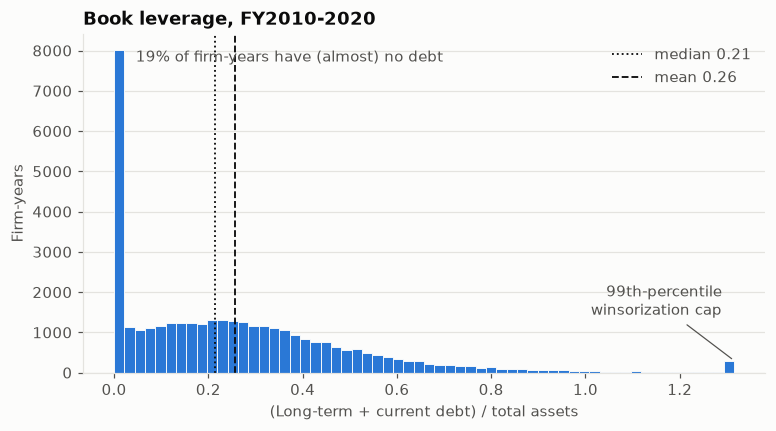

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(panel["leverage"], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.6)
for stat, ls in [("median", ":"), ("mean", "--")]:
    v = getattr(panel["leverage"], stat)()
    ax.axvline(v, color=INK, ls=ls, lw=1.2, label=f"{stat} {v:.2f}")
ax.legend(frameon=False, labelcolor=INK_2)
zero_share = (panel["leverage"] < 0.01).mean()
ax.annotate(f"{zero_share:.0%} of firm-years have (almost) no debt", (0.02, ax.get_ylim()[1] * 0.93),
            xytext=(8, 0), textcoords="offset points", va="center", color=INK_2)
ax.annotate("99th-percentile\nwinsorization cap", (panel["leverage"].max(), 300), xytext=(-8, 30),
            textcoords="offset points", ha="right", color=INK_2,
            arrowprops={"arrowstyle": "-", "color": INK_2, "lw": 0.8})
ax.set(title="Book leverage, FY2010-2020", xlabel="(Long-term + current debt) / total assets",
       ylabel="Firm-years")
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "cs_leverage_distribution.png")
plt.show()

Leverage is right-skewed, with two notable features:
- A **spike at zero**: about one firm-year in five carries essentially no debt. These "zero-leverage"
  firms are a documented puzzle in corporate finance, and are typically young, R&D-intensive and
  cash-rich.
- A **small mass at the cap** from firms with negative book equity, whose debt exceeds their assets.

Because the outcome is bounded below at zero, a linear model is an approximation. It still
estimates the average effect of each characteristic on the debt ratio, which is what the question
asks.

### 5.3 Leverage over time

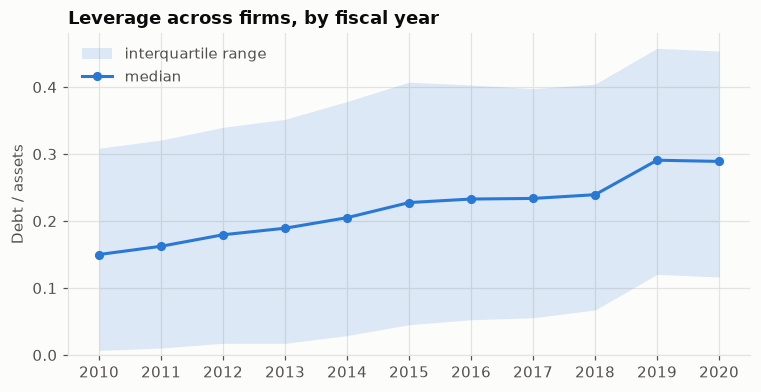

fyear,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0.250,0.007,0.010,0.018,0.017,0.029,0.045,0.053,0.056,0.067,0.120,0.116
0.500,0.150,0.162,0.180,0.189,0.205,0.228,0.233,0.234,0.239,0.291,0.289
0.750,0.309,0.321,0.340,0.352,0.378,0.407,0.403,0.398,0.404,0.458,0.454


In [23]:
by_year = panel.groupby("fyear")["leverage"].quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(by_year.index, by_year[0.25], by_year[0.75], color=BLUE, alpha=0.15, lw=0,
                label="interquartile range")
ax.plot(by_year.index, by_year[0.5], color=BLUE, lw=2, marker="o", ms=5, label="median")
ax.set(title="Leverage across firms, by fiscal year", ylabel="Debt / assets", ylim=(0, None))
ax.set_xticks(by_year.index)
ax.legend(frameon=False, labelcolor=INK_2, loc="upper left")
fig.savefig(FIG_DIR / "cs_leverage_by_year.png")
plt.show()
by_year.T.round(3)

- **Median leverage roughly doubled over the decade**, from 0.15 in 2010 to 0.29 in 2019–2020.
  The rise is gradual through 2018, consistent with a long period of cheap borrowing after the
  financial crisis.
- **The jump in 2019** coincides with the new lease-accounting standards (ASC 842 / IFRS 16), which
  brought operating leases onto the balance sheet. Part of this step is likely mechanical, coming
  from how lease obligations are recorded, rather than a change in borrowing behaviour.
- **The 25th percentile rises from almost 0 to 0.12**, so the share of firms with no debt shrinks
  over time.

Economy-wide shifts like these affect all firms in a year at once, and would be confused with
firm characteristics that also trend over time. This is why the main specification includes
**year fixed effects**.

### 5.4 Leverage across industries

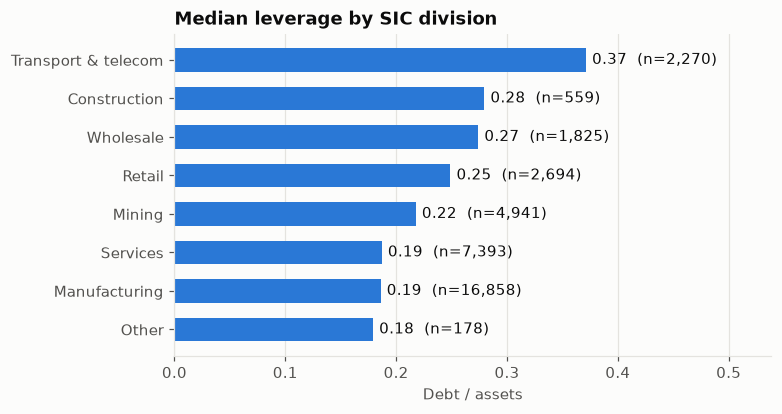

In [24]:
DIVISIONS = [(14, "Mining"), (17, "Construction"), (39, "Manufacturing"), (48, "Transport & telecom"),
             (51, "Wholesale"), (59, "Retail"), (89, "Services"), (99, "Other")]
panel["division"] = pd.cut(panel["sic2"], [0] + [hi for hi, _ in DIVISIONS],
                           labels=[lab for _, lab in DIVISIONS]).astype(str)
by_div = panel.groupby("division")["leverage"].agg(["median", "size"]).sort_values("median")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(by_div.index, by_div["median"], color=BLUE, height=0.6)
for y, (v, n) in enumerate(zip(by_div["median"], by_div["size"])):
    ax.annotate(f"{v:.2f}  (n={n:,})", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK)
ax.set(title="Median leverage by SIC division", xlabel="Debt / assets", xlim=(0, by_div["median"].max() * 1.45))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "cs_leverage_by_industry.png")
plt.show()

Industries differ substantially. Transport and telecom (0.37), with heavy fixed assets and stable
cash flows, carry the most debt. Construction, wholesale and retail (0.25–0.28) finance
inventories and receivables with debt. Manufacturing and services (0.19) are the least levered,
because they include the technology and pharmaceutical firms whose assets are largely
intangible. These differences motivate both the tangibility variable and the industry controls.

### 5.5 How leverage varies with each determinant

A scatter plot of 36,000 points is unreadable. Instead, each panel sorts firm-years into 20
equal-sized bins of the predictor and plots mean leverage in each bin, a **binned scatter**. This
shows the shape of each relationship (linear, curved, flat) before any model is imposed.

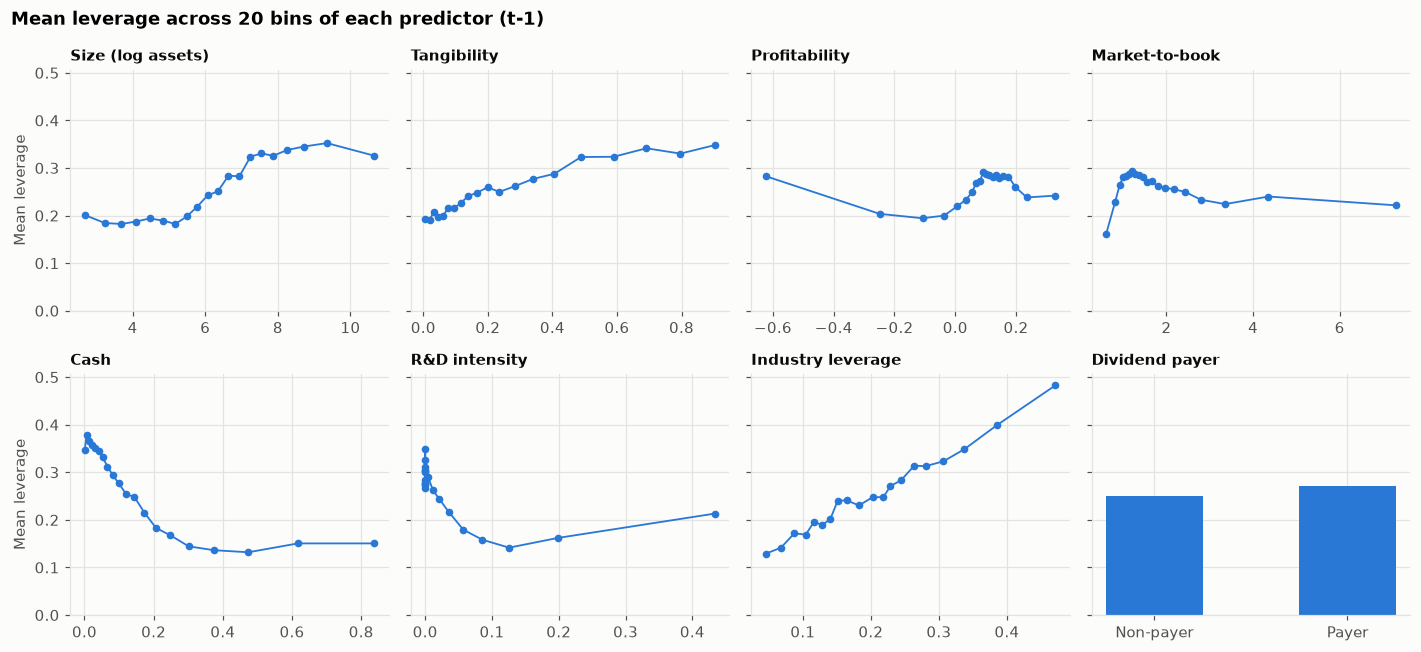

In [25]:
continuous = [p for p in PREDICTORS if p != "dividend_payer"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
for ax, var in zip(axes.flat, continuous):
    bins = pd.qcut(panel[var].rank(method="first"), 20, labels=False)
    binned = panel.groupby(bins).agg(x=(var, "mean"), y=("leverage", "mean"))
    ax.plot(binned["x"], binned["y"], color=BLUE, marker="o", ms=4, lw=1.2)
    ax.set_title(LABELS[var], fontsize=10)
axes.flat[-1].bar(["Non-payer", "Payer"], panel.groupby("dividend_payer")["leverage"].mean(), color=BLUE, width=0.5)
axes.flat[-1].set_title(LABELS["dividend_payer"], fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("Mean leverage")
fig.suptitle("Mean leverage across 20 bins of each predictor (t-1)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "cs_binned_scatter.png")
plt.show()

**What the shapes say.**
- **Industry leverage, tangibility** rise steadily: close to linear, as expected.
- **Cash** falls sharply from 0.38 to about 0.14 as cash rises to 30% of assets, then flattens.
  Firms with large cash piles have essentially no further reason to borrow.
- **Size** is flat for firms below about $250M of assets (log ≈ 5.5), then rises. Being large
  matters for access to debt markets, but only above a threshold.
- **Profitability** is non-monotonic. Leverage is high for heavy loss-makers (distressed firms
  whose debt is large relative to shrinking assets), lowest around break-even, peaks at moderate
  profitability, and falls again for the most profitable firms. These opposing segments cancel
  out, which is why the raw correlation in Section 6 is close to zero.
- **Market-to-book** is hump-shaped. Firms valued below book (MB < 1) have low leverage, and
  beyond about 1.2 leverage declines with growth opportunities, as theory predicts.
- **R&D intensity** lowers leverage at first. The top bin turns up again, likely biotech firms
  financed with convertible debt.
- **Dividend payers** have slightly *higher* raw leverage than non-payers. This is confounding:
  payers are much larger firms (correlation with size 0.42), and size raises leverage. Once the
  regression holds size fixed, the payer effect turns negative (Section 7).

The linear model will summarise each relationship by its average slope. The curvature here is
worth remembering when reading the coefficients.

## 6. Correlations and multicollinearity

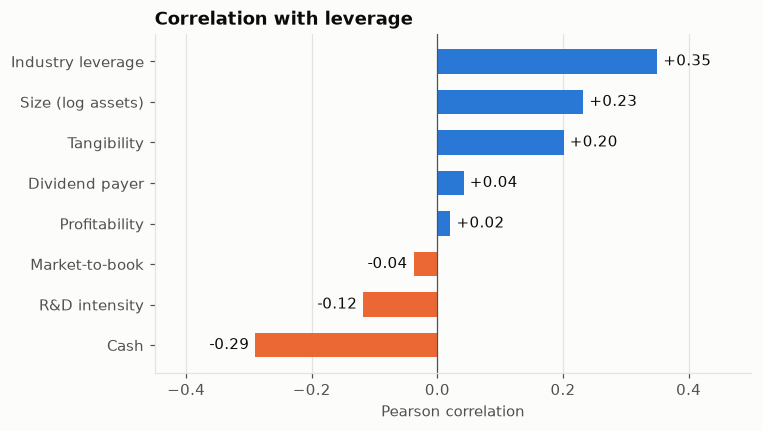

,Leverage,Size (log assets),Tangibility,Profitability,Market-to-book,Cash,R&D intensity,Dividend payer,Industry leverage
Leverage,1.00,0.23,0.20,0.02,-0.04,-0.29,-0.12,0.04,0.35
Size (log assets),0.23,1.00,0.14,0.38,-0.10,-0.31,-0.27,0.42,0.22
Tangibility,0.20,0.14,1.00,0.12,-0.23,-0.41,-0.30,0.08,0.31
Profitability,0.02,0.38,0.12,1.00,-0.14,-0.42,-0.62,0.33,0.12
Market-to-book,-0.04,-0.10,-0.23,-0.14,1.00,0.42,0.37,-0.06,-0.14
Cash,-0.29,-0.31,-0.41,-0.42,0.42,1.00,0.60,-0.24,-0.31
R&D intensity,-0.12,-0.27,-0.30,-0.62,0.37,0.60,1.00,-0.24,-0.26
Dividend payer,0.04,0.42,0.08,0.33,-0.06,-0.24,-0.24,1.00,0.17
Industry leverage,0.35,0.22,0.31,0.12,-0.14,-0.31,-0.26,0.17,1.00


In [26]:
corr = panel[["leverage"] + PREDICTORS].corr()
with_leverage = corr["leverage"].drop("leverage").sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([LABELS[i] for i in with_leverage.index], with_leverage,
        color=[BLUE if v > 0 else ORANGE for v in with_leverage], height=0.6)
ax.axvline(0, color=INK_2, lw=0.8)
for y, v in enumerate(with_leverage):
    ax.annotate(f"{v:+.2f}", (v, y), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                ha="left" if v > 0 else "right", va="center", color=INK)
ax.set(title="Correlation with leverage", xlabel="Pearson correlation", xlim=(-0.45, 0.5))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "cs_correlations.png")
plt.show()

corr.rename(index=LABELS, columns=LABELS).map("{:.2f}".format)

In [27]:
X = panel[PREDICTORS].assign(const=1.0).to_numpy()
vif = pd.Series([variance_inflation_factor(X, i) for i in range(len(PREDICTORS))],
                index=[LABELS[p] for p in PREDICTORS], name="VIF").sort_values(ascending=False)
vif.round(2).to_frame()

,VIF
R&D intensity,2.230
Cash,1.940
Profitability,1.860
Size (log assets),1.370
Tangibility,1.280
Market-to-book,1.280
Dividend payer,1.280
Industry leverage,1.200


**Interpretation.**
- **With leverage:** industry leverage, size and tangibility are positively correlated with
  leverage; cash and R&D intensity are negatively correlated. Profitability is close to zero in
  the raw correlation for two reasons: the relationship is non-monotonic (Section 5.5), and
  profitable firms tend to be large (correlation 0.38), and size raises leverage. Only a
  regression that holds size fixed can separate the two effects (Section 7).
- **Between predictors:** the strongest correlation is −0.62, between profitability and R&D
  intensity, because R&D-heavy firms are often loss-making. Cash, R&D and market-to-book form a
  cluster typical of growth firms. No VIF exceeds 2.3, far below the conventional threshold of 10,
  so every predictor can stay in the model without inflating standard errors.

## 7. Linear model of leverage

$$
\text{Leverage}_{it} = \alpha + \beta_1\,\text{Size}_{i,t-1} + \beta_2\,\text{Tangibility}_{i,t-1}
+ \beta_3\,\text{Profitability}_{i,t-1} + \beta_4\,\text{MB}_{i,t-1} + \beta_5\,\text{Cash}_{i,t-1}
+ \beta_6\,\text{R\&D}_{i,t-1} + \beta_7\,\text{Div}_{i,t-1} + \beta_8\,\text{IndLev}_{i,t-1}
+ \gamma' \text{Controls}_{i,t-1} + \mu_j + \lambda_t + \varepsilon_{it}
$$

Each $\beta$ is the change in the debt ratio for a one-unit change in the predictor, holding the
others fixed. The controls are the R&D-not-reported flag and the CAD-reporter flag. Three
specifications are estimated, all by OLS:

1. **Pooled OLS**, with no fixed effects. This is the baseline the assignment asks for.
2. **OLS with industry ($\mu_j$, 2-digit SIC) and year ($\lambda_t$) dummies.** This compares firms
   within the same industry and year, removing macro shocks and industry-wide norms.
3. **Firm and year fixed effects.** Each firm gets its own intercept, so the slopes are identified
   only from changes *within* a firm over time.

**Standard errors.** The same firm appears up to 11 times, and its errors are correlated across
years. Conventional OLS standard errors assume independence and would be too small. All standard
errors are therefore **clustered by firm**.

### 7.1 Specification (1): pooled OLS, full output

In [28]:
rhs = " + ".join(PREDICTORS + CONTROLS)
firm_clusters = {"groups": pd.factorize(panel["gvkey"])[0]}

ols = smf.ols(f"leverage ~ {rhs}", panel).fit(cov_type="cluster", cov_kwds=firm_clusters)
print(ols.summary(slim=True))

                            OLS Regression Results                            
Dep. Variable:               leverage   R-squared:                       0.214
Model:                            OLS   Adj. R-squared:                  0.214
No. Observations:               36718   F-statistic:                     236.3
Covariance Type:              cluster   Prob (F-statistic):               0.00
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.0304      0.011      2.650      0.008       0.008       0.053
size                  0.0224      0.001     15.173      0.000       0.020       0.025
tangibility           0.0342      0.013      2.701      0.007       0.009       0.059
profitability        -0.1697      0.017     -9.833      0.000      -0.204      -0.136
market_to_book        0.0166      0.002      7.988      0.000       0.012       0.021
cas

**Reading the output.**
- **Fit:** R² = 0.214, and the F-statistic of 236 (p < 0.001) rejects the hypothesis that all slopes
  are zero.
- **Every determinant is significant at the 1% level**, with z-statistics (estimate / clustered SE)
  ranging from 2.6 for R&D to over 20 for cash and industry leverage.
- **Controls:** firms that do not report R&D carry 1.9 pp more debt than reported-zero firms, and
  CAD reporters carry 3.2 pp less, so both flags are worth keeping.
- **Signs** are as expected for size, tangibility, profitability, cash and industry leverage.
  Market-to-book and R&D have the "wrong" sign here, which the next specifications investigate.

### 7.2 Specifications (2) and (3)

In [29]:
ols_fe = smf.ols(f"leverage ~ {rhs} + C(sic2) + C(fyear)", panel).fit(
    cov_type="cluster", cov_kwds=firm_clusters)

# cad_reporter never changes within a firm, so the firm effect absorbs it.
fe_data = panel.set_index(["gvkey", "fyear"])
firm_fe = PanelOLS(fe_data["leverage"], fe_data[PREDICTORS + ["rd_missing"]],
                   entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)

print(f"(2) adds {panel['sic2'].nunique() - 1} industry and {panel['fyear'].nunique() - 1} year dummies: "
      f"R² rises from {ols.rsquared:.3f} to {ols_fe.rsquared:.3f}")
print(f"(3) F-test that all firm effects are zero: F = {firm_fe.f_pooled.stat:.2f}, "
      f"p = {firm_fe.f_pooled.pval:.4f}")

(2) adds 62 industry and 10 year dummies: R² rises from 0.214 to 0.248
(3) F-test that all firm effects are zero: F = 14.55, p = 0.0000


**What changes.**
- **Adding industry and year dummies (2)** raises R² by 3.4 points. The **tangibility** coefficient
  more than triples, from 0.034 to 0.119. Across industries, tangibility is confounded with
  industry type: service and technology firms have few tangible assets, but differ in other ways
  too. Comparing firms *within* the same industry isolates the collateral effect. The coefficient
  on industry leverage falls from 0.59 to 0.39 because the dummies take over part of its role, and
  R&D becomes insignificant.
- **Firm effects (3)** are jointly highly significant (F = 14.6, p < 0.0001). Firms differ in
  persistent, unobserved ways that pooled OLS leaves in the error term. Specification (3) is the
  cleanest test of whether a *change* in a characteristic is associated with a change in leverage.

### 7.3 Side-by-side results

In [30]:
def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


def column(res, footer):
    """Coefficient on one row, clustered standard error in parentheses beneath it."""
    se = res.bse if hasattr(res, "bse") else res.std_errors
    labels, cells = [], []
    for v in PREDICTORS:
        labels += [LABELS[v], ""]
        cells += [f"{res.params[v]:.4f}{stars(res.pvalues[v])}", f"({se[v]:.4f})"]
    return pd.Series(cells + list(footer.values()), index=labels + list(footer))


results = pd.DataFrame({
    "(1) Pooled OLS": column(ols, {"Industry & year effects": "No", "Firm effects": "No",
                                   "R²": f"{ols.rsquared:.3f}"}),
    "(2) OLS + industry & year": column(ols_fe, {"Industry & year effects": "Yes", "Firm effects": "No",
                                                 "R²": f"{ols_fe.rsquared:.3f}"}),
    "(3) Firm & year FE": column(firm_fe, {"Industry & year effects": "Year", "Firm effects": "Yes",
                                           "R²": f"{firm_fe.rsquared:.3f} (within)"}),
})
results = pd.concat([results, pd.DataFrame({c: [f"{len(panel):,}"] for c in results}, index=["Observations"])])
print("Coefficients with firm-clustered standard errors in parentheses. *** p<0.01, ** p<0.05, * p<0.1")
results

Coefficients with firm-clustered standard errors in parentheses. *** p<0.01, ** p<0.05, * p<0.1


,(1) Pooled OLS,(2) OLS + industry & year,(3) Firm & year FE
Size (log assets),0.0224***,0.0236***,0.0211***
,(0.0015),(0.0014),(0.0046)
Tangibility,0.0342***,0.1190***,0.1166***
,(0.0127),(0.0178),(0.0263)
Profitability,-0.1697***,-0.1775***,-0.0979***
,(0.0173),(0.0170),(0.0181)
Market-to-book,0.0166***,0.0147***,-0.0004
,(0.0021),(0.0020),(0.0019)
Cash,-0.3134***,-0.3238***,-0.1323***
,(0.0152),(0.0156),(0.0169)


### 7.4 Economic magnitude

Raw coefficients are hard to compare because the predictors have very different scales. The chart
shows the change in leverage, in percentage points, from a one-standard-deviation increase in each
predictor (or from 0 to 1 for the dividend-payer dummy), using specification (2).

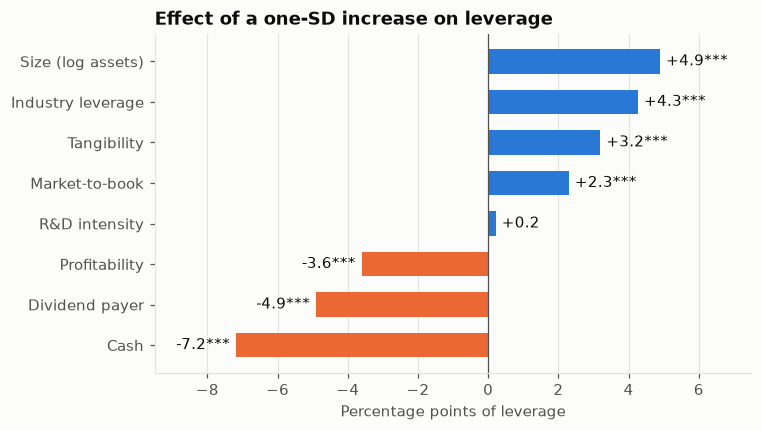

,(1) Pooled OLS,(2) + industry & year,(3) Firm & year FE
Size (log assets),+4.6,+4.9,+4.4
Tangibility,+0.9,+3.2,+3.1
Profitability,-3.4,-3.6,-2.0
Market-to-book,+2.6,+2.3,-0.1
Cash,-6.9,-7.2,-2.9
R&D intensity,+1.1,+0.2,-0.4
Dividend payer,-4.7,-4.9,+0.0
Industry leverage,+6.4,+4.3,+3.1


In [31]:
def effects(res):
    sd = panel[PREDICTORS].std().where(lambda s: s.index != "dividend_payer", 1.0)
    return pd.DataFrame({"effect_pp": 100 * res.params[PREDICTORS] * sd, "p": res.pvalues[PREDICTORS]})


eff = effects(ols_fe).sort_values("effect_pp")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([LABELS[i] for i in eff.index], eff["effect_pp"],
        color=[BLUE if v > 0 else ORANGE for v in eff["effect_pp"]], height=0.6)
ax.axvline(0, color=INK_2, lw=0.8)
for y, (v, p) in enumerate(zip(eff["effect_pp"], eff["p"])):
    ax.annotate(f"{v:+.1f}{stars(p)}", (v, y), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                ha="left" if v > 0 else "right", va="center", color=INK)
ax.set(title="Effect of a one-SD increase on leverage", xlabel="Percentage points of leverage",
       xlim=(-9.5, 7.5))
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "cs_standardized_effects.png")
plt.show()

pd.concat({"(1) Pooled OLS": effects(ols)["effect_pp"], "(2) + industry & year": effects(ols_fe)["effect_pp"],
           "(3) Firm & year FE": effects(firm_fe)["effect_pp"]}, axis=1).rename(index=LABELS).map("{:+.1f}".format)

### 7.5 Residual check

OLS does not require normal errors for unbiased coefficients, but the residuals show where the
linear model fits poorly.

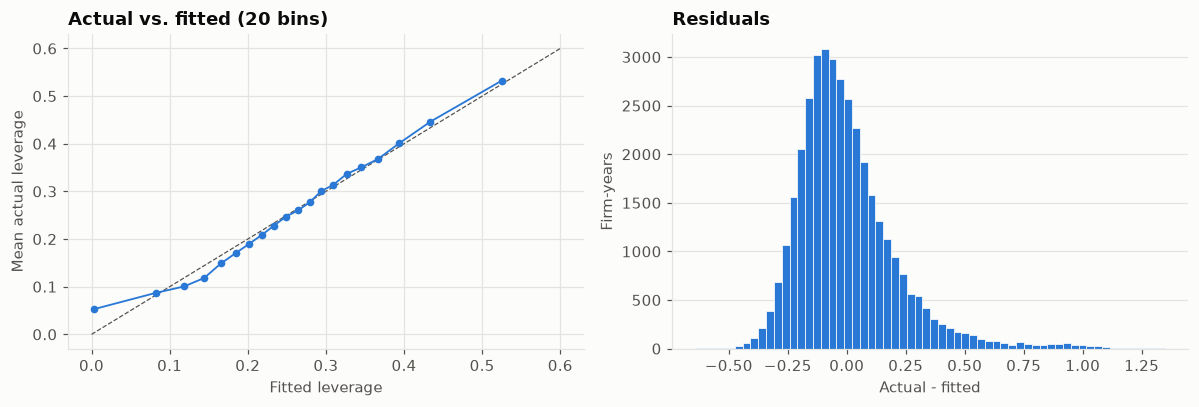

Share of fitted values below zero: 1.8%


In [32]:
fitted, resid = ols_fe.fittedvalues, ols_fe.resid
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = pd.qcut(fitted.rank(method="first"), 20, labels=False)
binned = pd.DataFrame({"fitted": fitted, "actual": panel["leverage"]}).groupby(bins).mean()
axes[0].plot([0, 0.6], [0, 0.6], color=INK_2, lw=0.8, ls="--")
axes[0].plot(binned["fitted"], binned["actual"], color=BLUE, marker="o", ms=4, lw=1.2)
axes[0].set(title="Actual vs. fitted (20 bins)", xlabel="Fitted leverage", ylabel="Mean actual leverage")
axes[1].hist(resid, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="Residuals", xlabel="Actual - fitted", ylabel="Firm-years")
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()
print(f"Share of fitted values below zero: {(fitted < 0).mean():.1%}")

- **Calibration:** the binned actual-vs-fitted points lie close to the 45° line across most of
  the range, so the linear specification captures the average relationship well.
- **Floor at zero:** the fit breaks down only at the bottom. Firms predicted to have zero leverage
  actually average about 0.05, because leverage cannot be negative while 1.8% of fitted values
  are.
- **Skewed residuals:** the right tail shows that the model under-predicts the most indebted firms,
  mirroring the skew of the outcome.

A fractional-response or Tobit model would respect the bounds, but the linear model is adequate
for the average effects that the assignment asks about.

## 8. Interpretation

**Important factors.** Specification (2), the preferred pooled model, gives these effects:

- **Cash (−7.2 pp per SD)** has the largest effect. Firms holding liquid assets need less external
  finance, and cash is partly "negative debt".
- **Size (+4.9 pp)** is the largest positive effect. A firm with twice the assets has about 1.6 pp
  higher leverage (0.024 × ln 2). Large firms have more stable cash flows and lower expected
  distress costs, as the trade-off theory predicts.
- **Industry leverage (+4.3 pp)** and **tangibility (+3.2 pp)**: firms borrow more in industries
  where debt is the norm and when they have collateral to pledge.
- **Profitability (−3.6 pp)**: a 10-point rise in EBITDA/assets lowers leverage by about 1.8 pp.
  Profitable firms retain earnings instead of borrowing, which is the pecking-order prediction
  and contradicts the simple trade-off view. The sign is negative once size is held constant,
  even though the raw correlation is near zero (Section 6).
- **Dividend payers (−4.9 pp)** are mature, low-information-asymmetry firms that rely less on debt.
- **Market-to-book (+2.3 pp)** has the *opposite* sign to theory in pooled data. A likely reason
  is that firms with depressed or negative book equity mechanically have both high debt/assets
  and high market-to-book. Within firms, in (3), the effect disappears.

**Within-firm results (3).** Size, tangibility, profitability, cash and industry leverage keep their
signs and remain significant when firm fixed effects are added, so these relationships are not
just differences between firm types. Market-to-book and dividend status lose significance: they
mostly distinguish *which* firms are levered, not *when* a firm adds debt.

**R-squared.** Pooled OLS explains **21.4%** of the variation in leverage, and adding industry and
year effects raises this to **24.8%**. In the firm fixed-effects model the within-R² is **3.4%**:
year-to-year changes in a firm's characteristics explain little of its year-to-year changes in
leverage. This is a well-known pattern (Lemmon, Roberts & Zender 2008). Leverage is highly
persistent, and the firm effects absorb most of the explainable variation, which is the cross-firm
variation that the pooled models fit.

**Limitations.** These are conditional correlations, not causal effects. Lagging the predictors
reduces simultaneity but does not remove omitted-variable bias. The sample is restricted to
non-financial firms with at least $10M of assets, and the results should not be extrapolated to
banks or micro-caps.